In [3]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import time
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Core crack_seg imports
from crack_seg import config
from crack_seg.data_handlers.dataset import CrackDataset
from crack_seg.data_handlers.dataset_loaders import (
    load_multiple_datasets,
    get_train_val_test_datasets,
    create_splits,
)
from crack_seg.data_handlers.transforms import (
    train_transform,
    val_transform,
    pred_transform,
    original_size_transform,
)
from crack_seg.data_handlers.class_imbalance import (
    compute_crack_pixel_proportion,
    format_class_imbalance_report,
)
from crack_seg.utils.visualization import display_prediction, compare_prediction
from crack_seg.utils.helpers import (
    load_model,
    load_model_from_checkpoint,
    plot_loss_curve,
    create_red_overlay,
    predict_yolo_mask,
)
from crack_seg.utils.post_processing import analyze_cracks
from crack_seg.predict import predict, predict_with_patches

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Using device from config:", config.DEVICE)

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(config.DEVICE)
    print(f"GPU Name:           {props.name}")
    print(f"Total VRAM:         {props.total_memory / (1024**3):.2f} GB")
    print(f"Compute Capability: {props.major}.{props.minor}")


PyTorch version: 2.10.0+cu128
CUDA available: True
Using device from config: cuda
GPU Name:           NVIDIA GeForce RTX 5060 Ti
Total VRAM:         7.96 GB
Compute Capability: 12.0


Loading UNet model...
Loading SegFormer model...
Loading YOLO model...

Found 6 bridge image(s). Running inference...

  2401-Mar-11-2021 (46).jpg                                    | UNet: 2.08s | SegFormer: 1.58s | YOLO: 0.29s


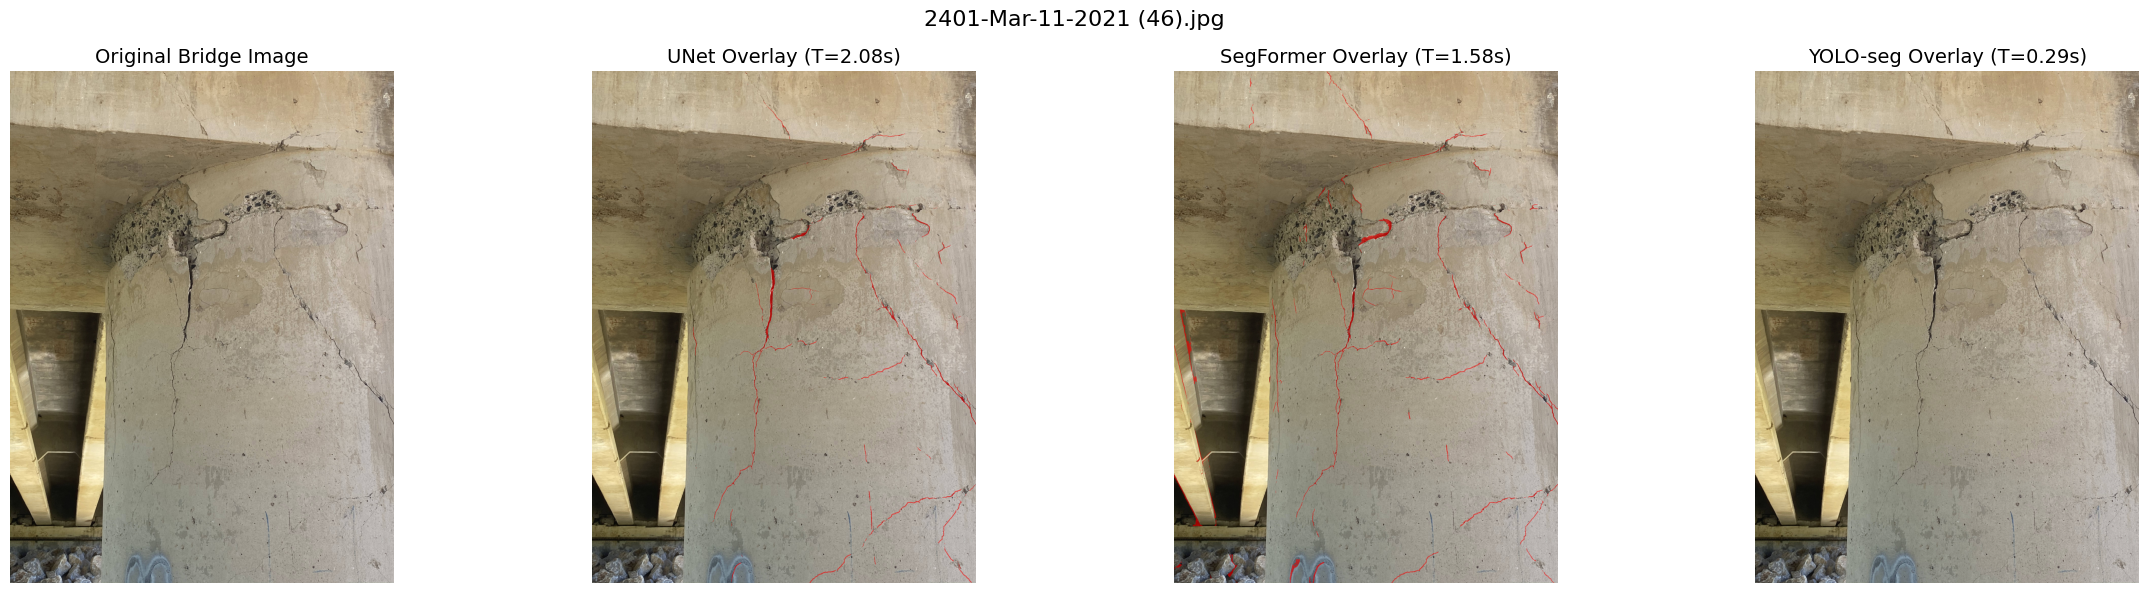

  2401-Mar-11-2021 (47).jpg                                    | UNet: 1.81s | SegFormer: 1.54s | YOLO: 0.12s


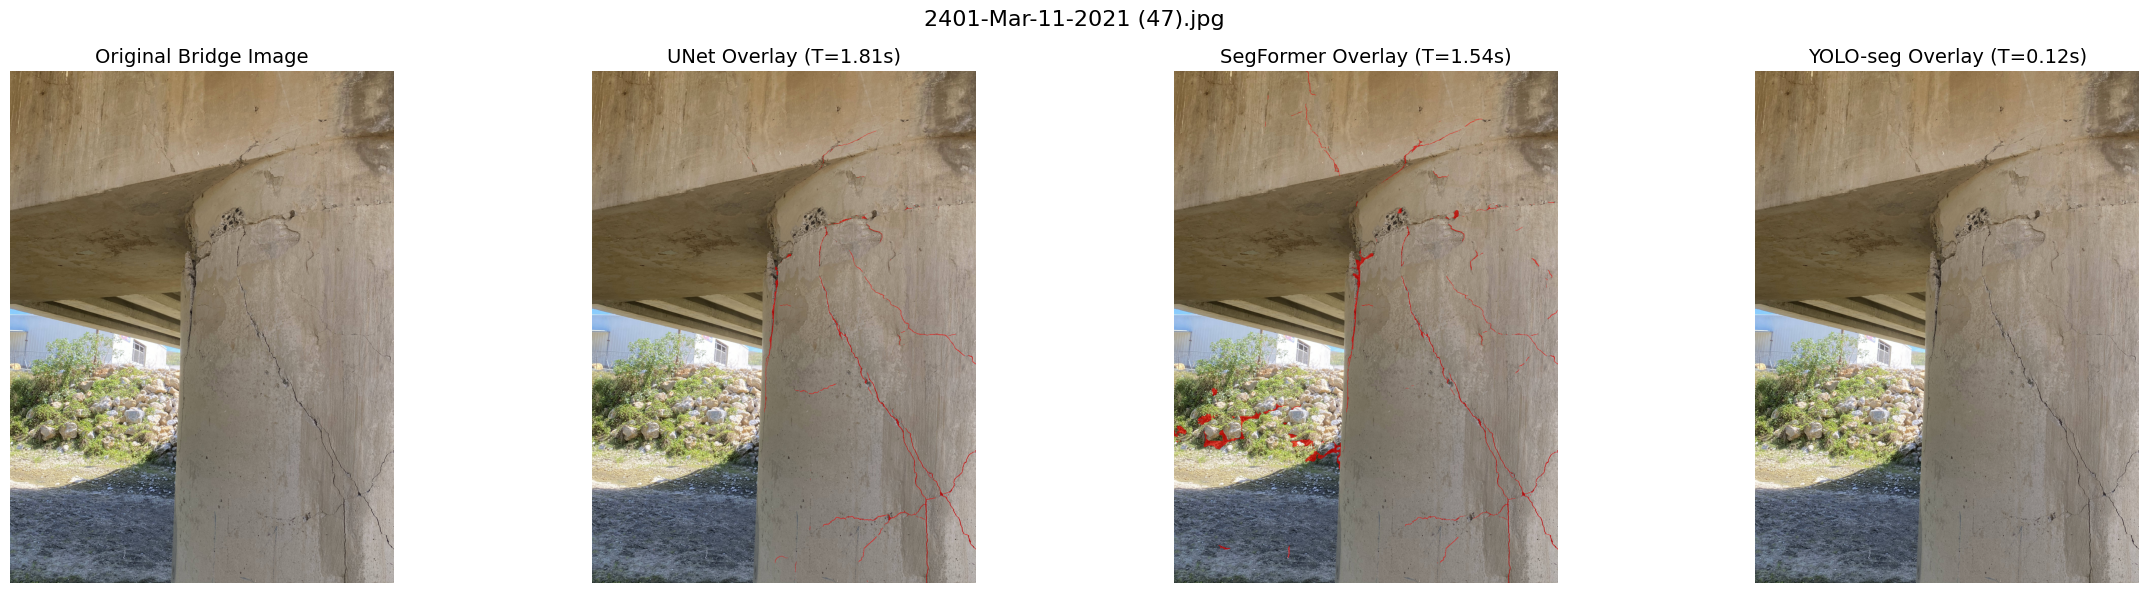

  2401-Mar-11-2021 (59).JPG                                    | UNet: 0.52s | SegFormer: 0.39s | YOLO: 0.07s


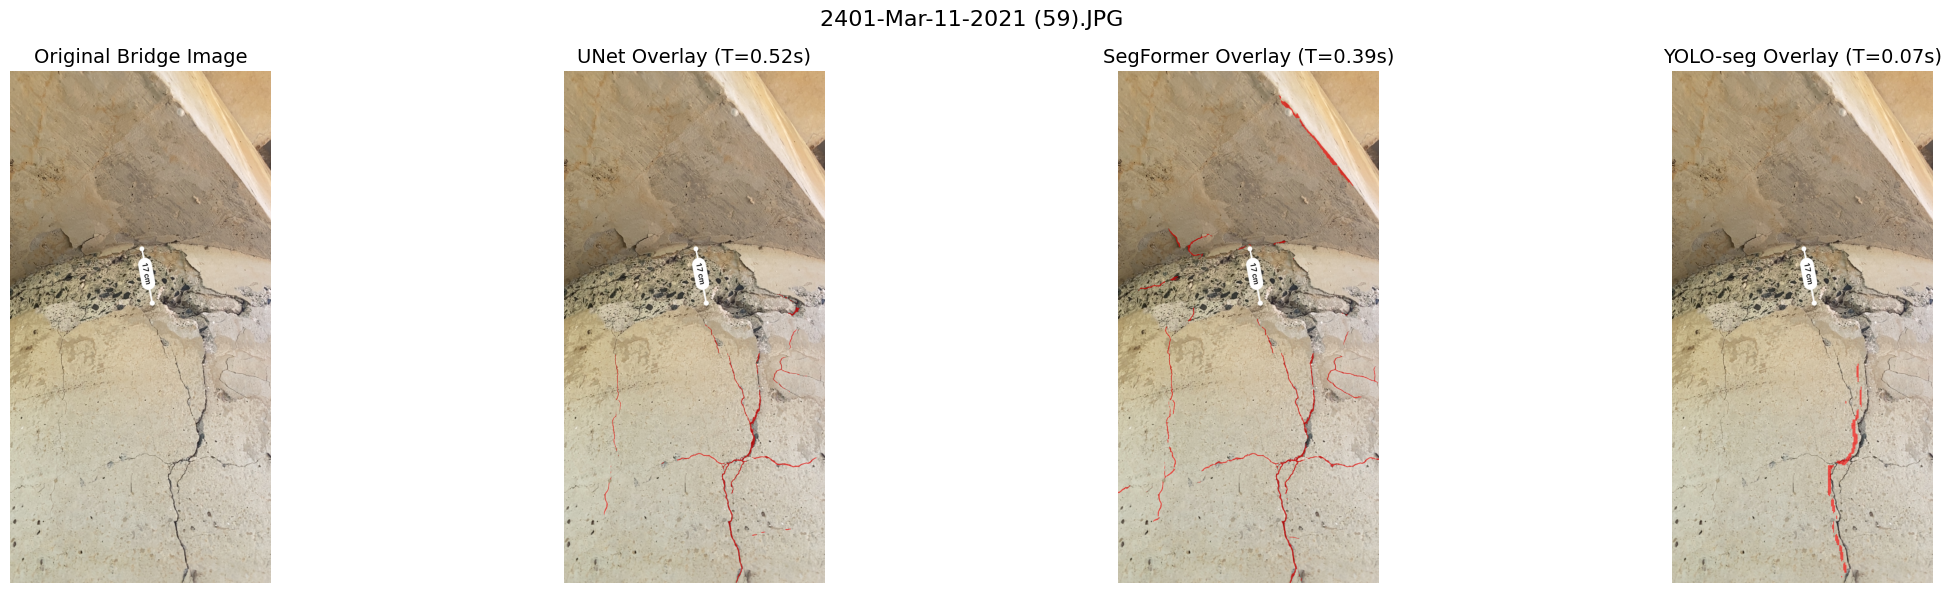

  learningfromearthquakes.org-2011-03-11-tohoku-japan-P1040451.jpg | UNet: 1.81s | SegFormer: 1.56s | YOLO: 0.30s


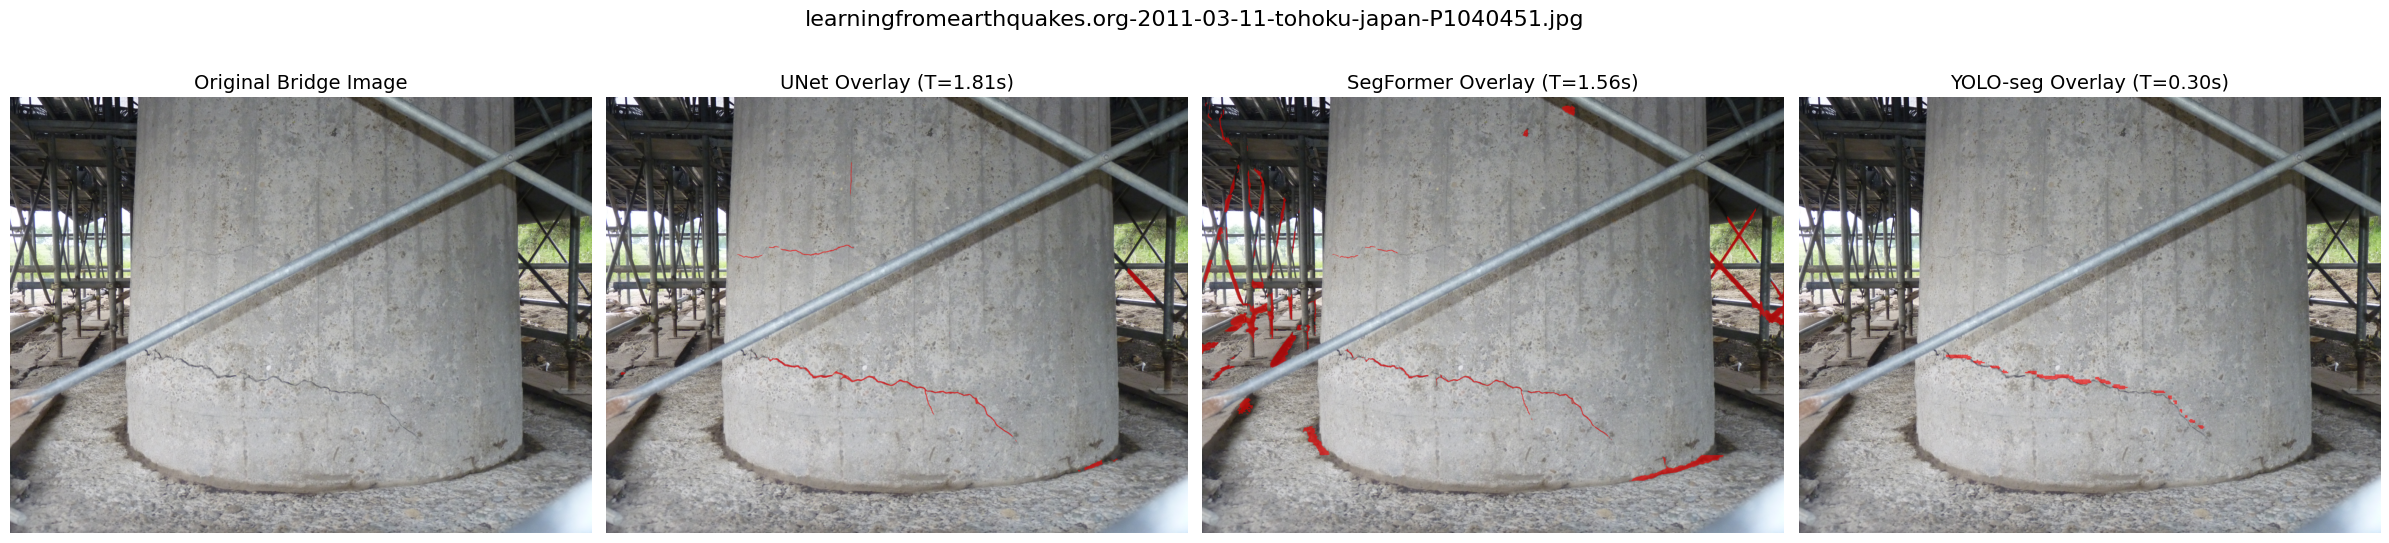

  learningfromearthquakes.org-2011_03_11_tohoku_japan-P1040486.jpg | UNet: 1.86s | SegFormer: 1.57s | YOLO: 0.72s


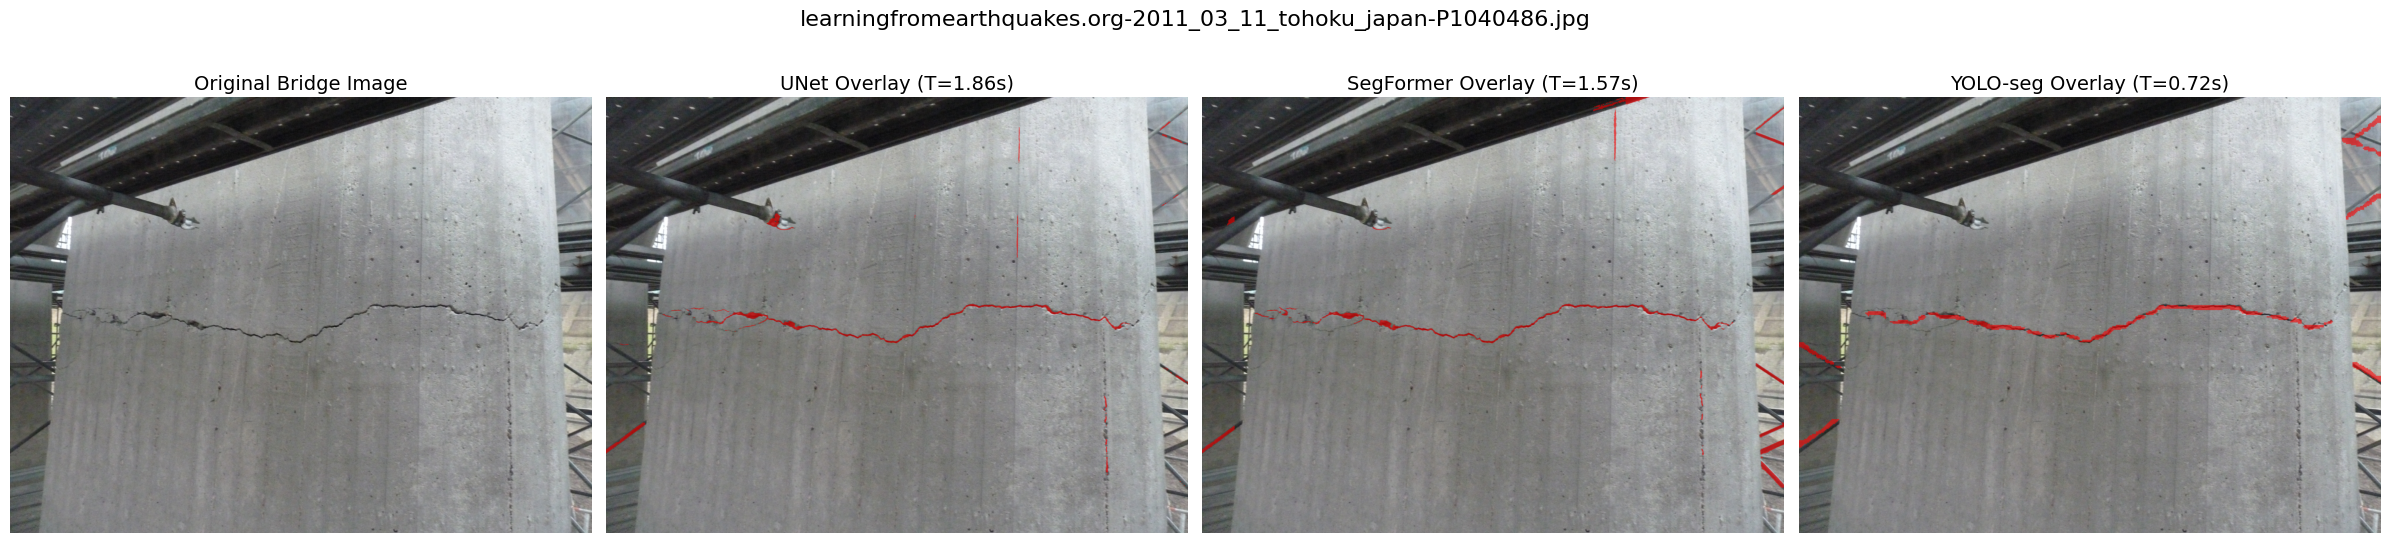

  test_image.jpg                                               | UNet: 1.22s | SegFormer: 2.13s | YOLO: 0.14s


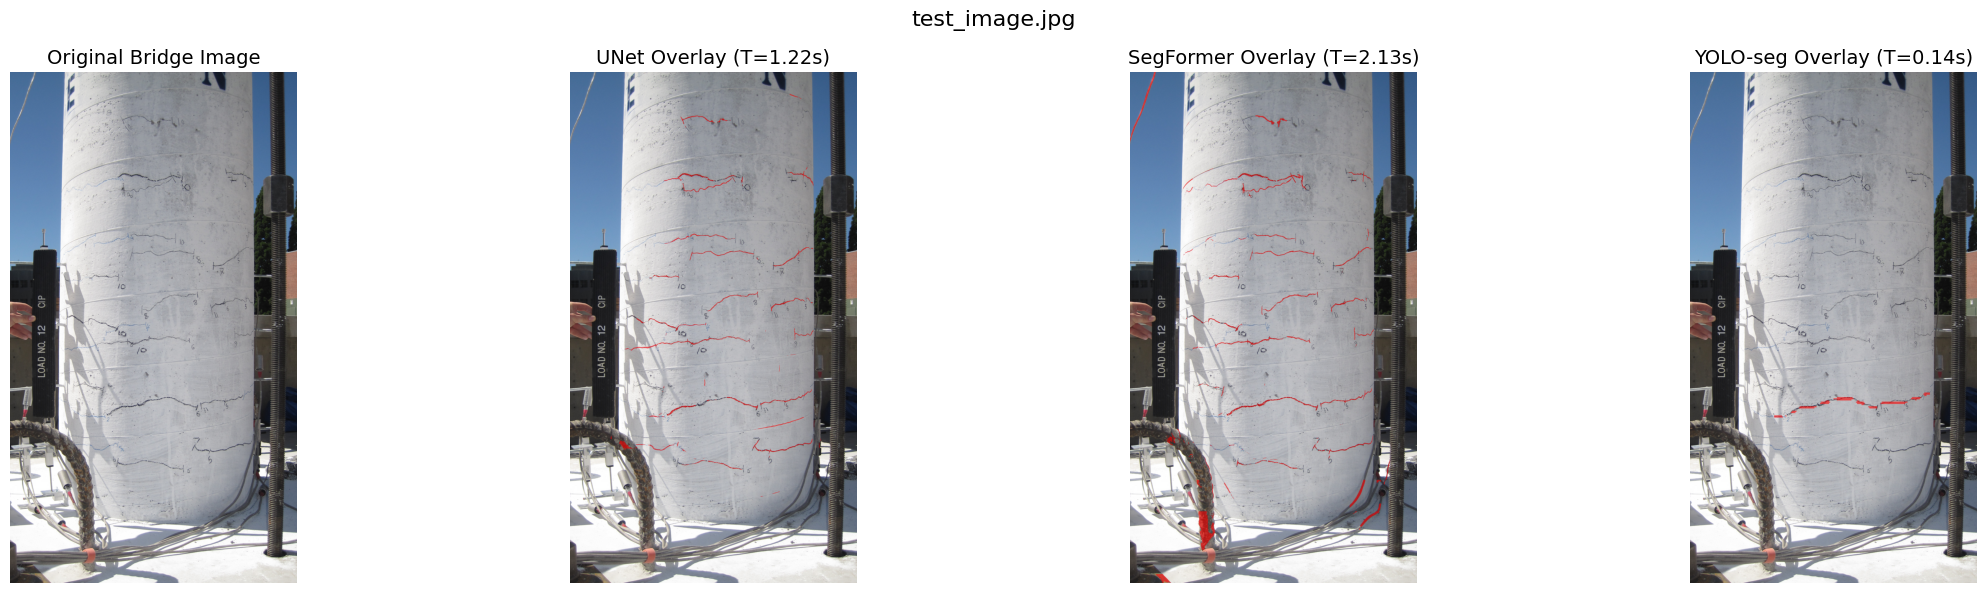

In [4]:
# Model checkpoint paths
unet_checkpoint = config.CHECKPOINT_DIR / "unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
segformer_checkpoint = config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
yolo_checkpoint = config.CHECKPOINT_DIR / "yolo_runs" / "yolo_seg_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pt"

# Load UNet, SegFormer, and YOLO models
print("Loading UNet model...")
unet_model = load_model("unet", unet_checkpoint, device=config.DEVICE)

print("Loading SegFormer model...")
segformer_model = load_model("segformer", segformer_checkpoint, device=config.DEVICE)

print("Loading YOLO model...")
yolo_model = load_model("yolo", yolo_checkpoint, device=config.DEVICE)


# Discover real bridge images
bridge_dir = config.DATA_ROOT / "real_bridge_sample"
if not bridge_dir.exists():
    raise FileNotFoundError(f"Bridge image directory not found: {bridge_dir}")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
bridge_images = sorted(
    path for path in bridge_dir.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)

if not bridge_images:
    raise FileNotFoundError(f"No image files found in {bridge_dir}")

print(f"\nFound {len(bridge_images)} bridge image(s). Running inference...\n")

# Run inference and display 4 subimages side by side for each bridge image
for image_path in bridge_images:
    bridge_img = Image.open(image_path).convert("RGB")
    
    # 1. UNet prediction with patches + timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    unet_pred = predict_with_patches(
        image_path=image_path,
        model=unet_model,
        device=config.DEVICE,
        patch_size=448,
        stride=224,
    ) > 0.5
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    unet_time = time.perf_counter() - t0
    
    # 2. SegFormer prediction with patches + timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    segformer_pred = predict_with_patches(
        image_path=image_path,
        model=segformer_model,
        device=config.DEVICE,
        patch_size=448,
        stride=224,
    ) > 0.5
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    segformer_time = time.perf_counter() - t0
    
    # 3. YOLO-seg prediction + timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    yolo_pred = predict_yolo_mask(image_path, yolo_model, conf=0.15)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    yolo_time = time.perf_counter() - t0

    print(f"  {image_path.name:<60} | UNet: {unet_time:.2f}s | SegFormer: {segformer_time:.2f}s | YOLO: {yolo_time:.2f}s")
    
    # Create red overlays
    unet_overlay = create_red_overlay(bridge_img, unet_pred, alpha=0.6)
    segformer_overlay = create_red_overlay(bridge_img, segformer_pred, alpha=0.6)
    yolo_overlay = create_red_overlay(bridge_img, yolo_pred, alpha=0.6)

    # Plot 4 subimages side by side with execution time in titles
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(image_path.name, fontsize=16)

    axes[0].imshow(bridge_img)
    axes[0].set_title("Original Bridge Image", fontsize=14)
    axes[0].axis("off")

    axes[1].imshow(unet_overlay)
    axes[1].set_title(f"UNet Overlay (T={unet_time:.2f}s)", fontsize=14)
    axes[1].axis("off")

    axes[2].imshow(segformer_overlay)
    axes[2].set_title(f"SegFormer Overlay (T={segformer_time:.2f}s)", fontsize=14)
    axes[2].axis("off")

    axes[3].imshow(yolo_overlay)
    axes[3].set_title(f"YOLO-seg Overlay (T={yolo_time:.2f}s)", fontsize=14)
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()


Loading UNet model...
Loading SegFormer model...
Loading YOLO model...

Found 10 bridge image(s). Running inference...

  IMG_0731.jpeg                                                | UNet: 2.76s | SegFormer: 2.70s | YOLO: 0.23s


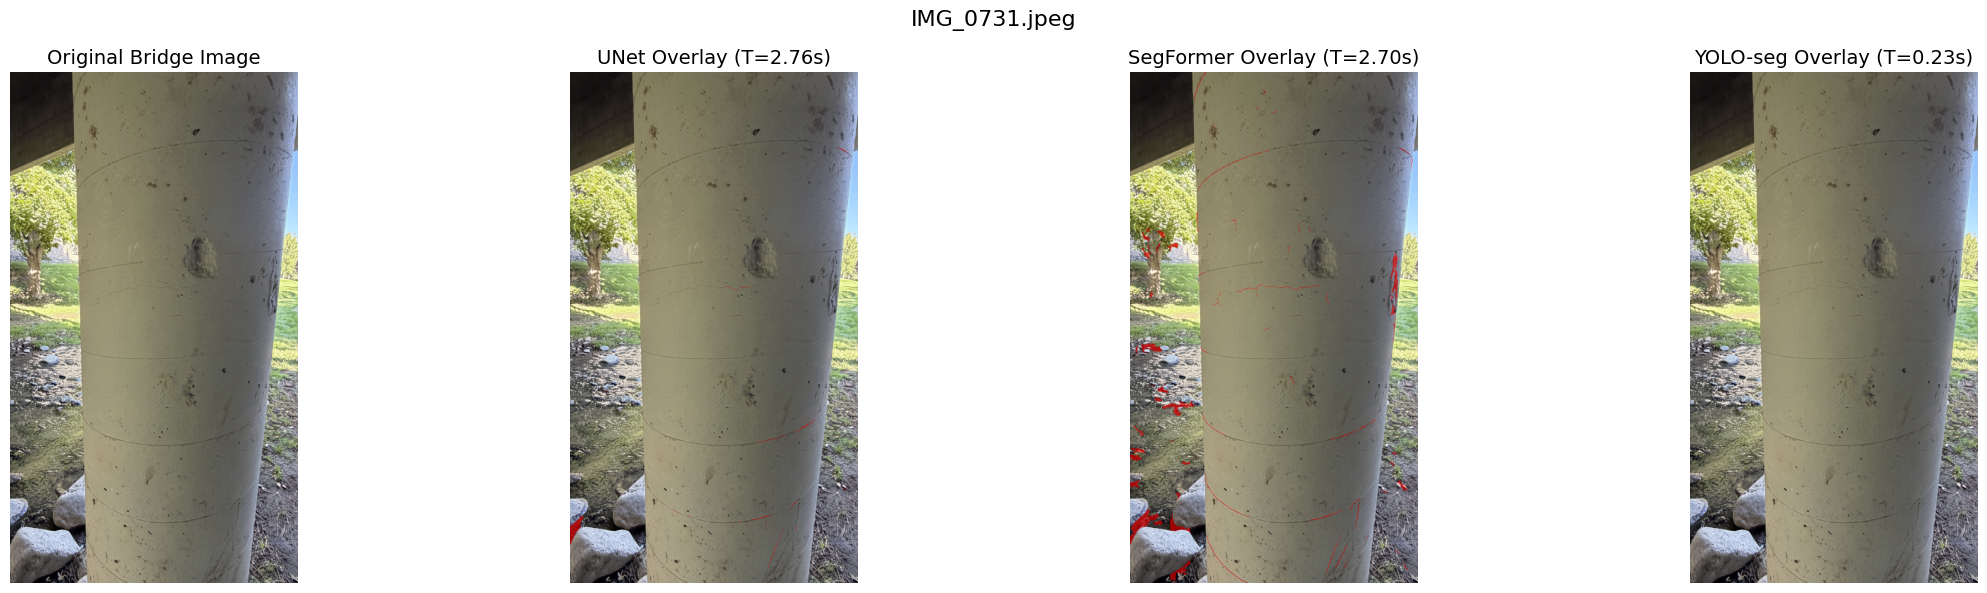

  IMG_0732.jpeg                                                | UNet: 2.77s | SegFormer: 2.35s | YOLO: 0.19s


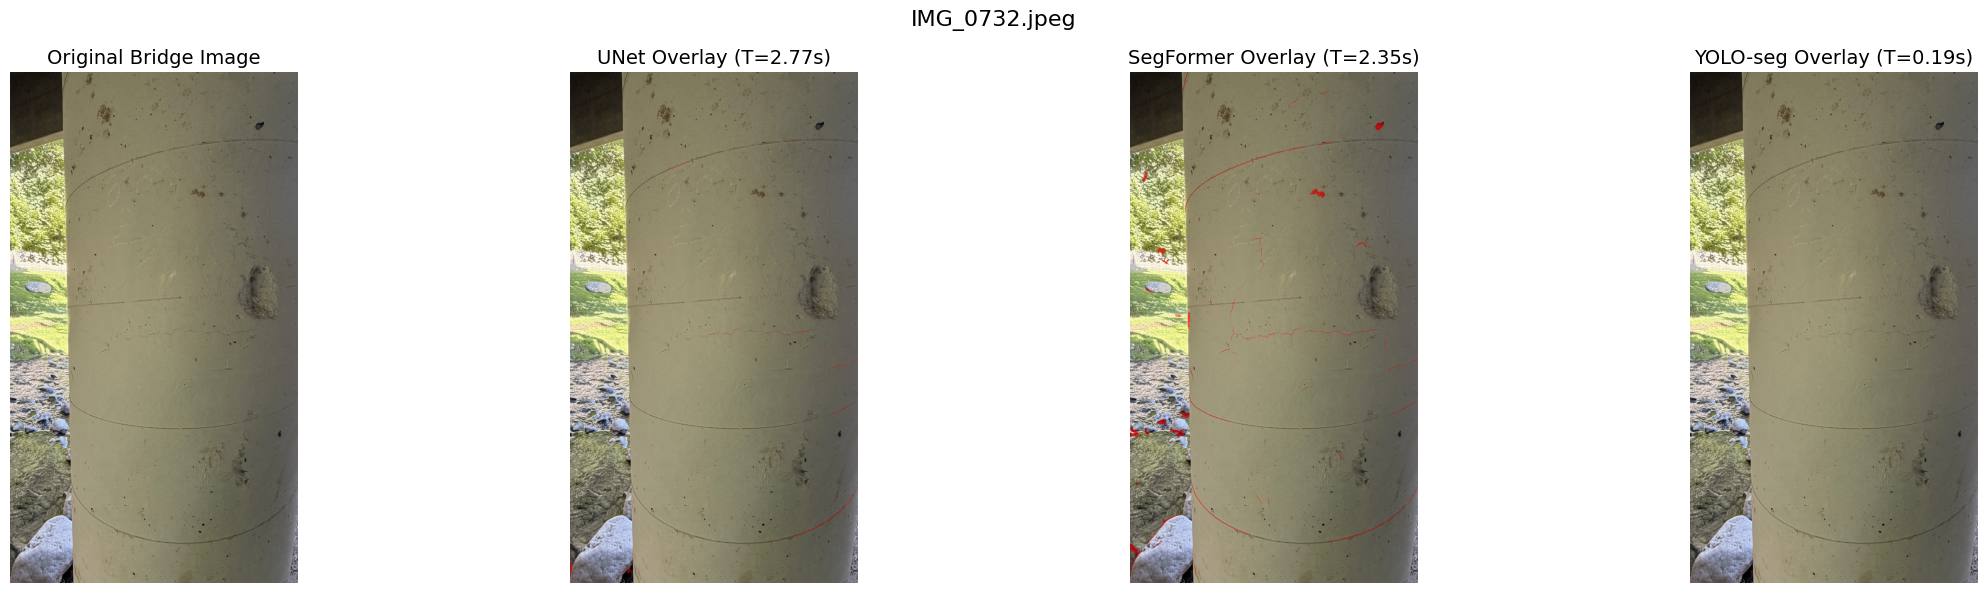

  IMG_0733.jpeg                                                | UNet: 2.78s | SegFormer: 2.36s | YOLO: 0.31s


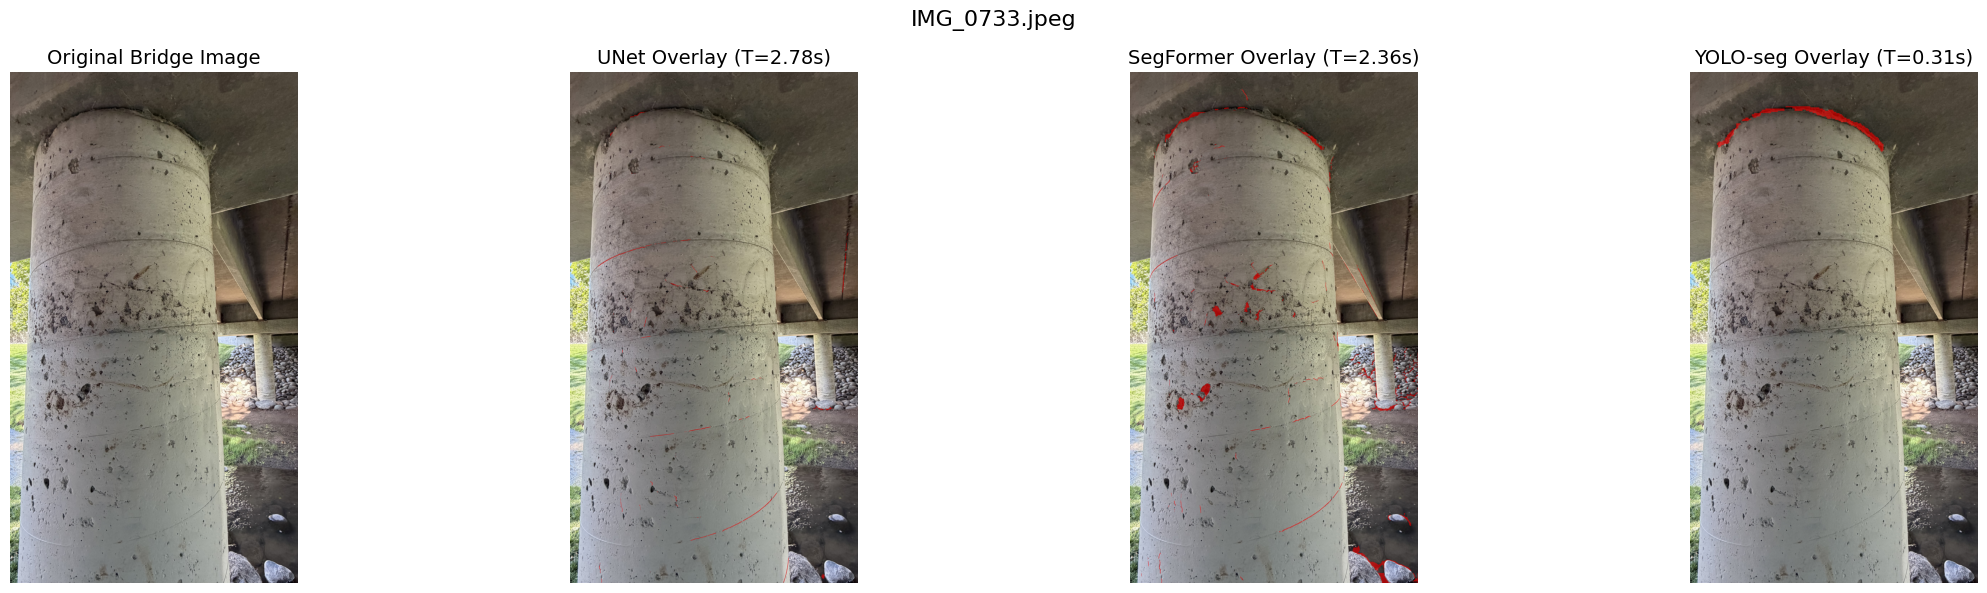

  IMG_0734.jpeg                                                | UNet: 2.72s | SegFormer: 2.31s | YOLO: 0.17s


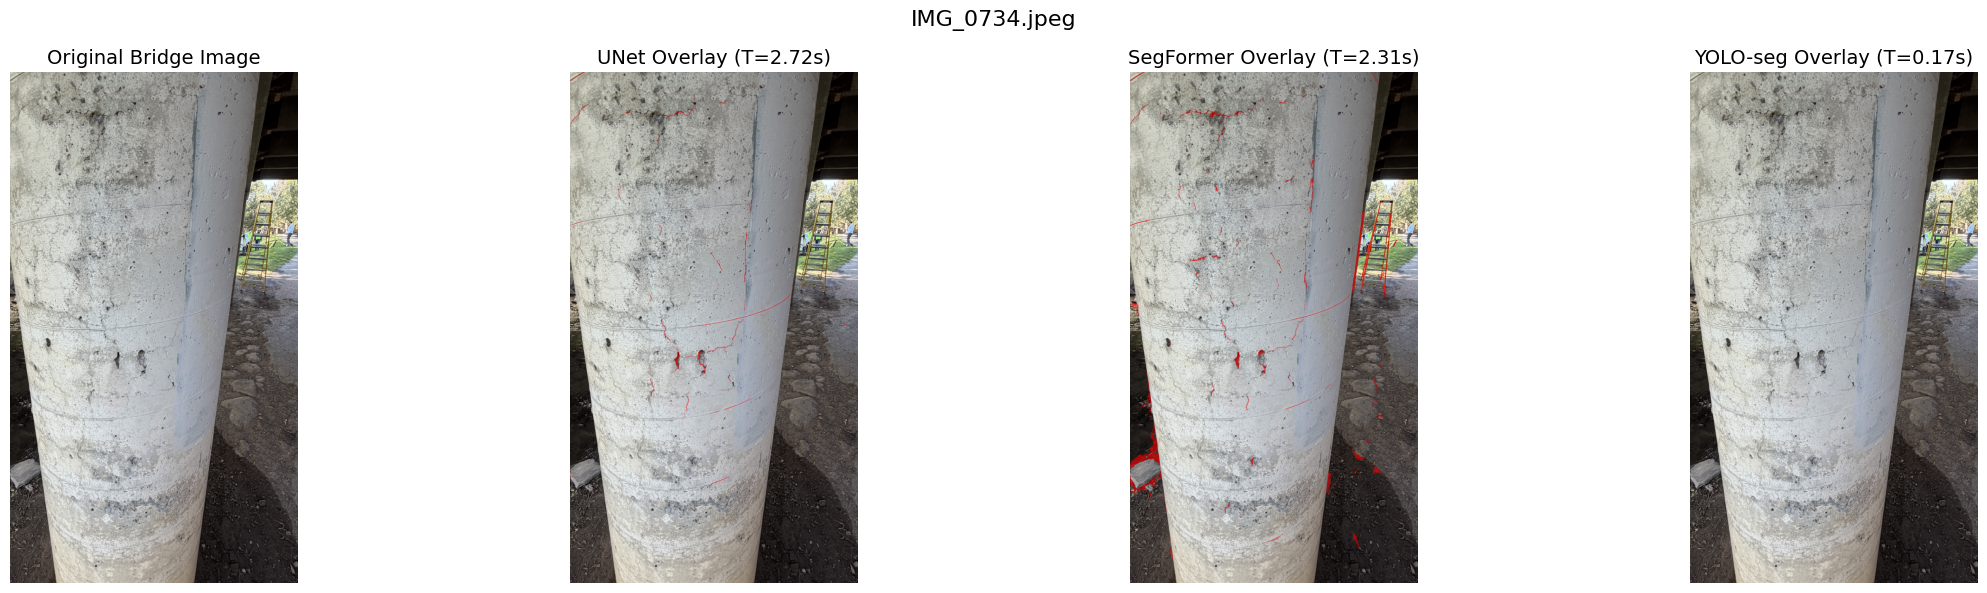

  IMG_0735.jpeg                                                | UNet: 2.70s | SegFormer: 2.32s | YOLO: 0.33s


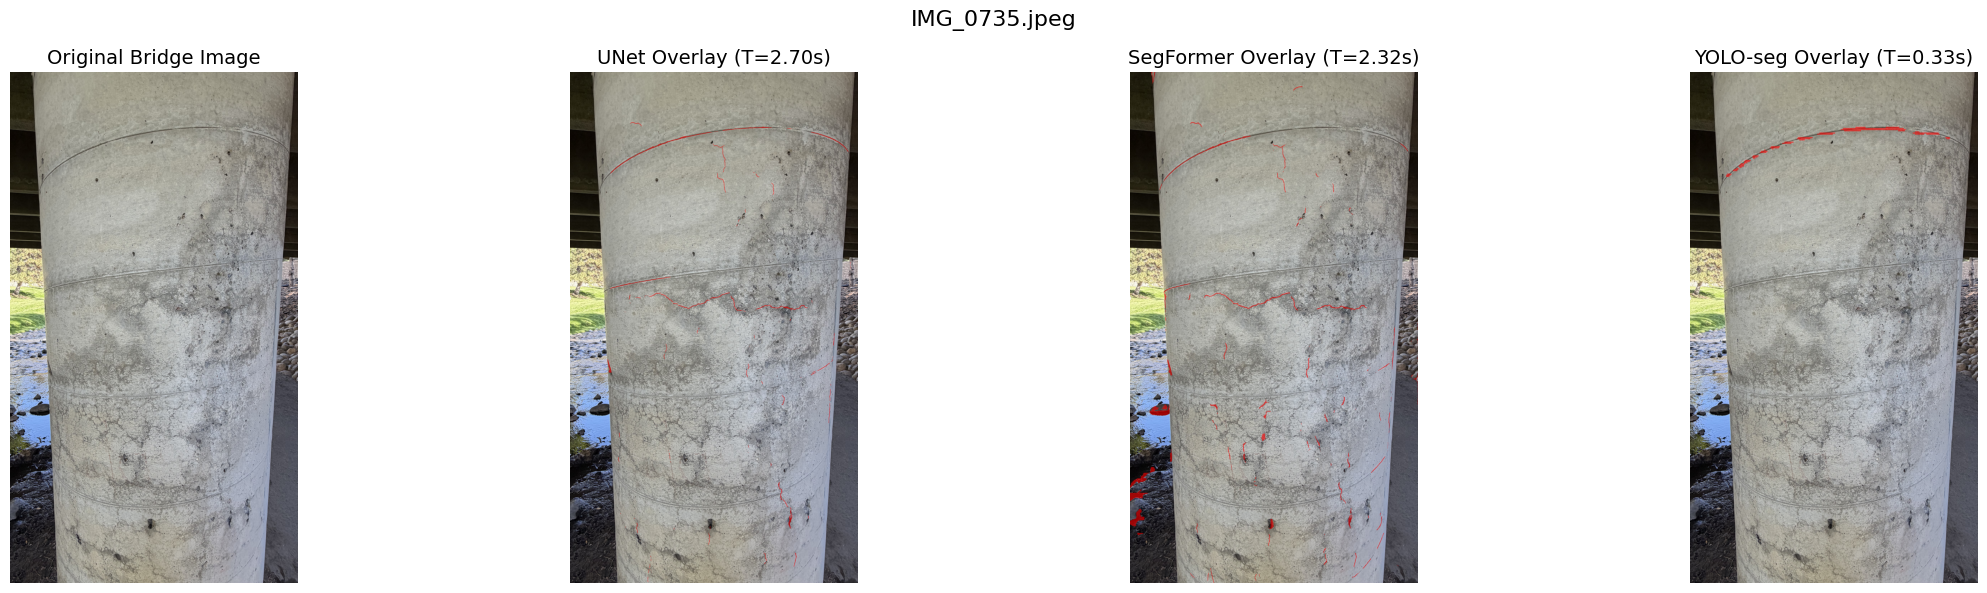

  IMG_0736.jpeg                                                | UNet: 2.76s | SegFormer: 2.32s | YOLO: 0.16s


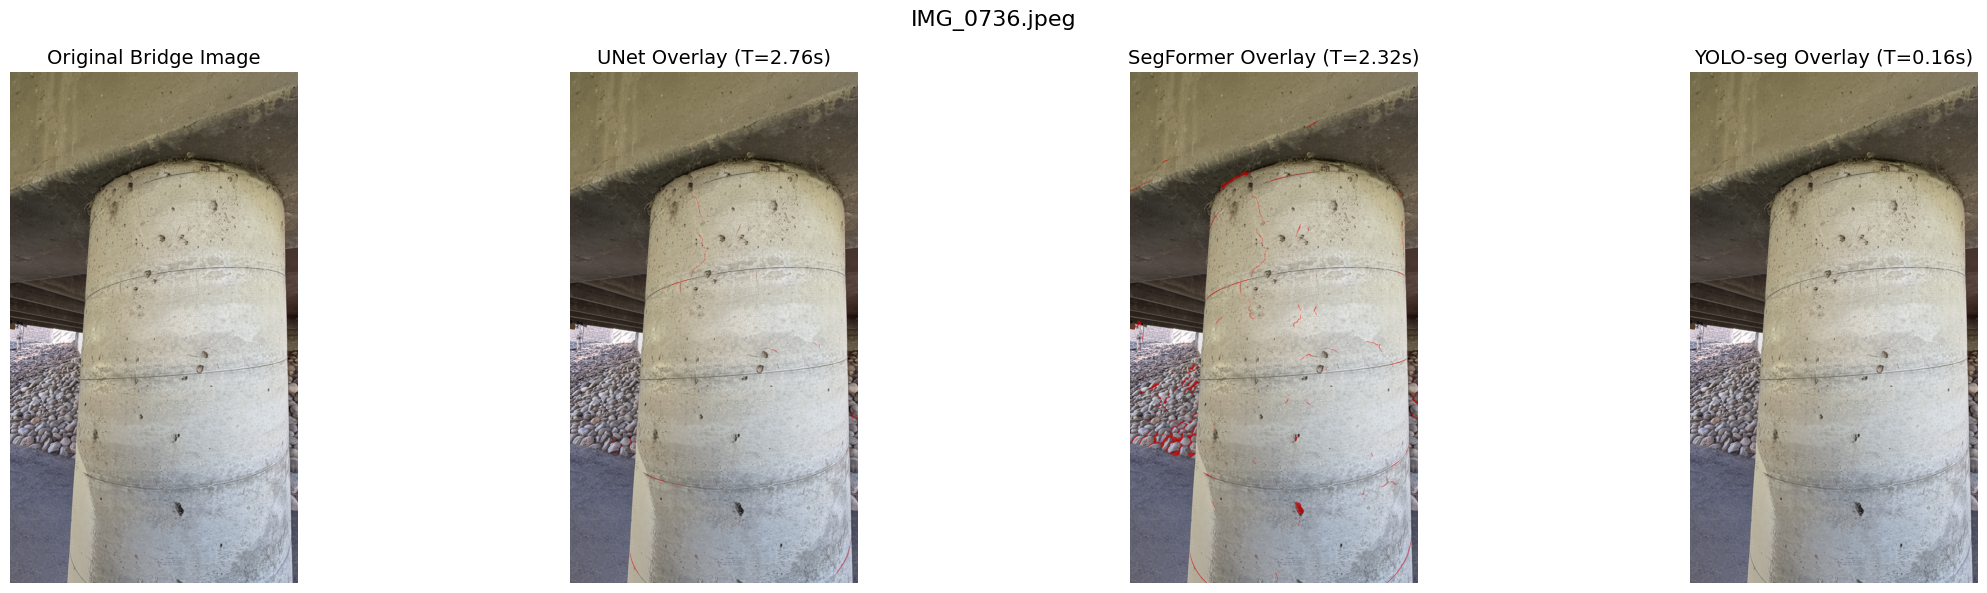

  IMG_0737.jpeg                                                | UNet: 2.73s | SegFormer: 2.34s | YOLO: 0.18s


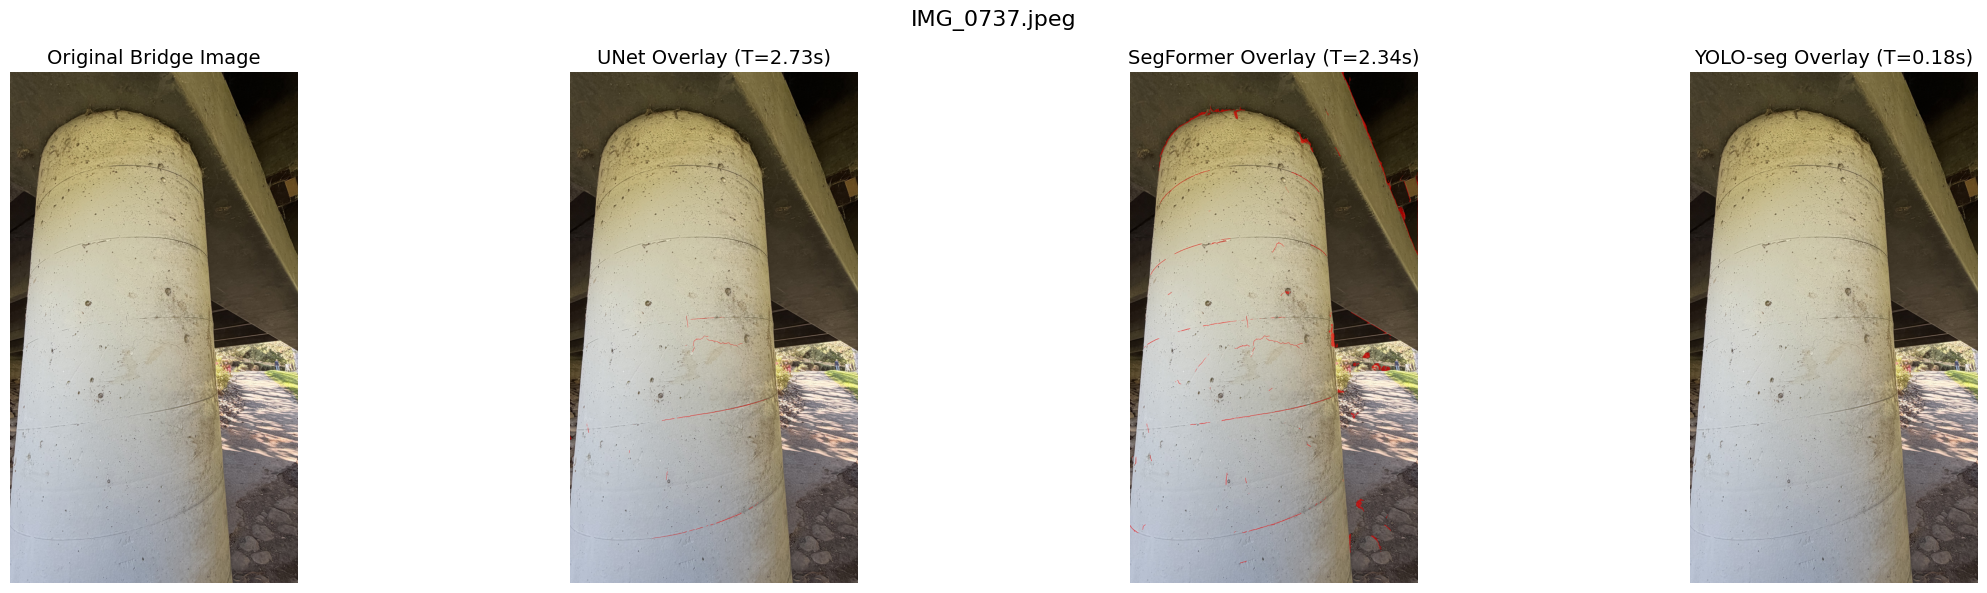

  IMG_0739.jpeg                                                | UNet: 2.74s | SegFormer: 2.35s | YOLO: 0.48s


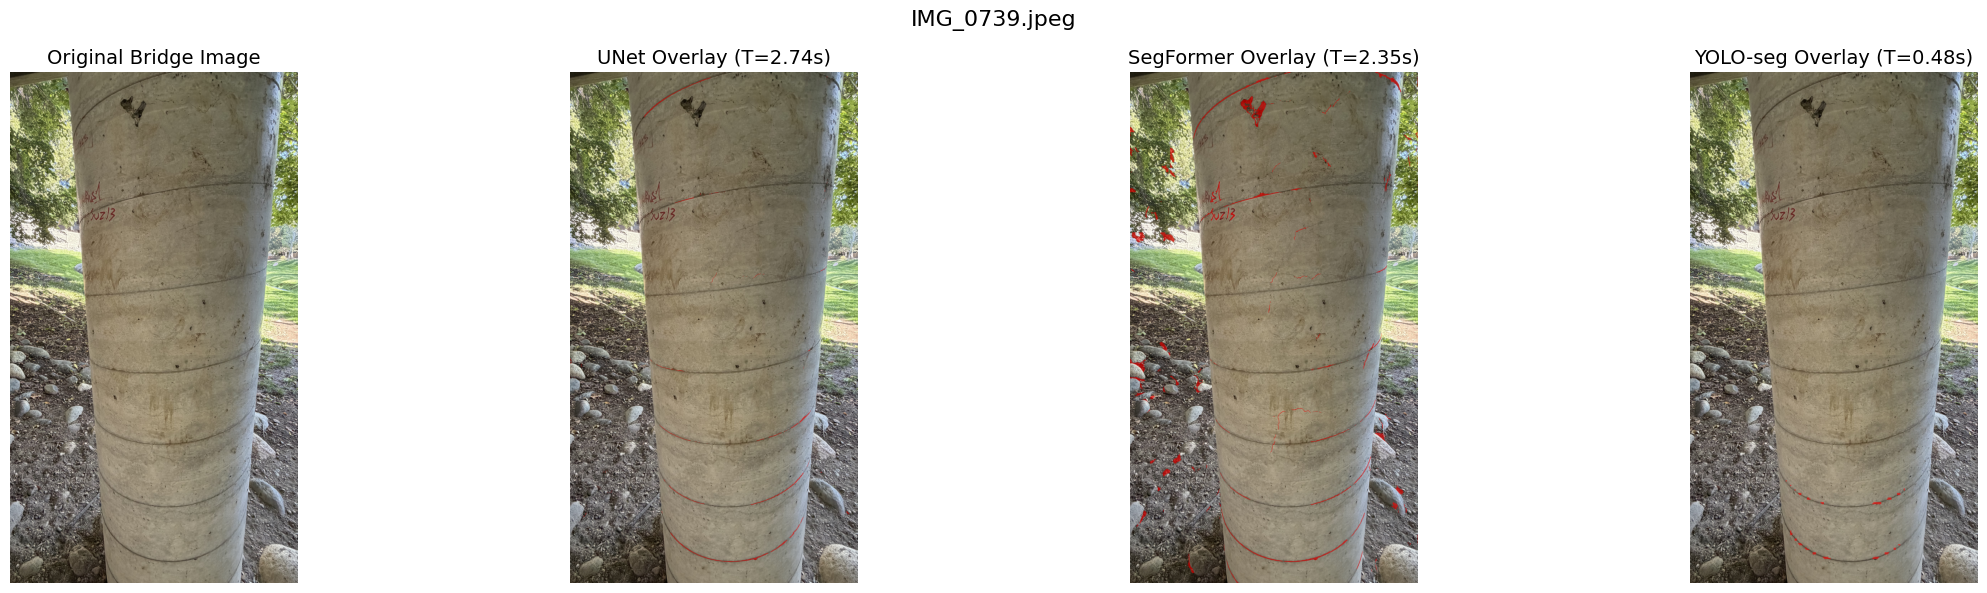

  IMG_0740.jpeg                                                | UNet: 2.74s | SegFormer: 2.30s | YOLO: 0.16s


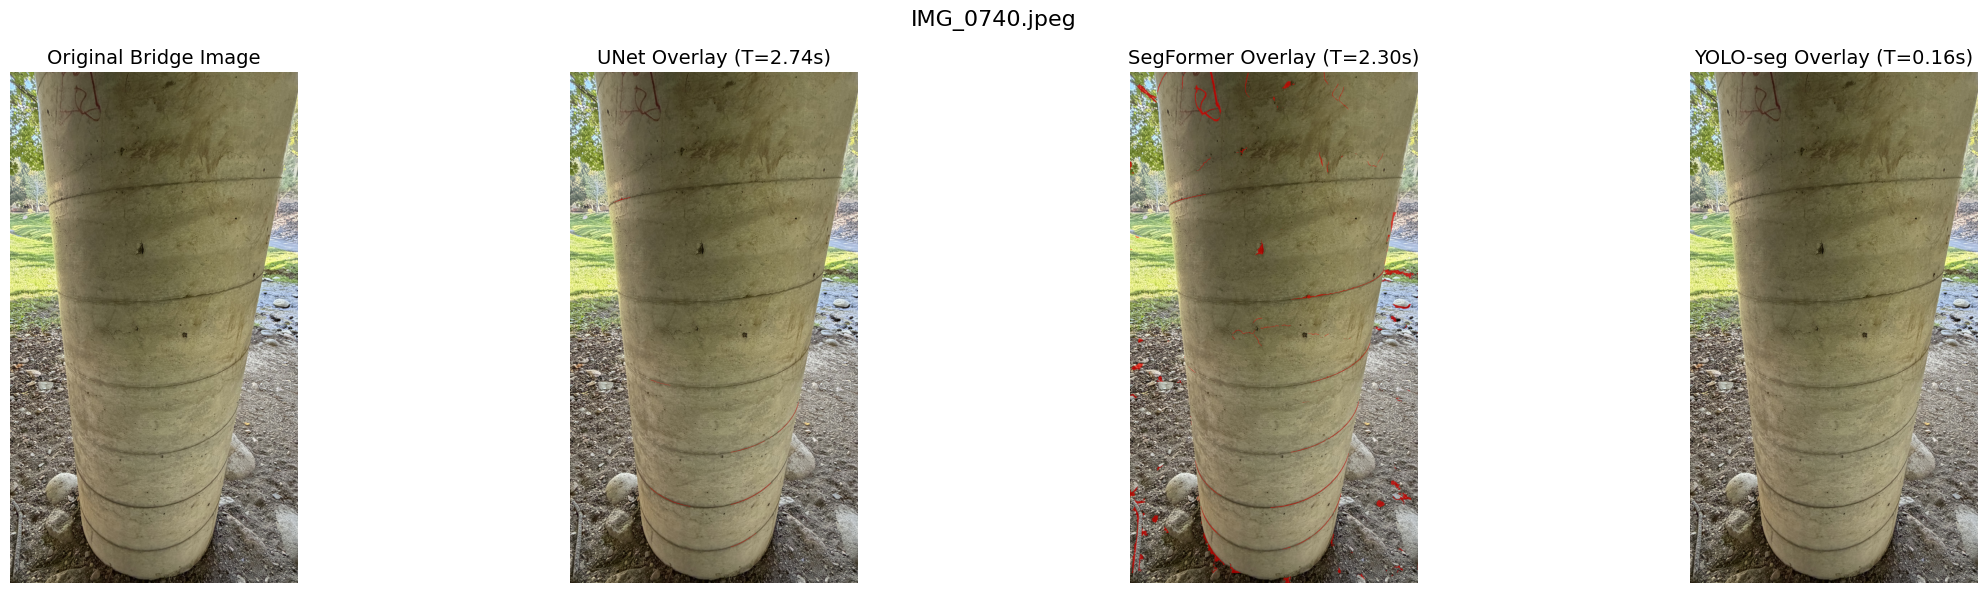

  IMG_0741.jpeg                                                | UNet: 2.69s | SegFormer: 2.29s | YOLO: 0.16s


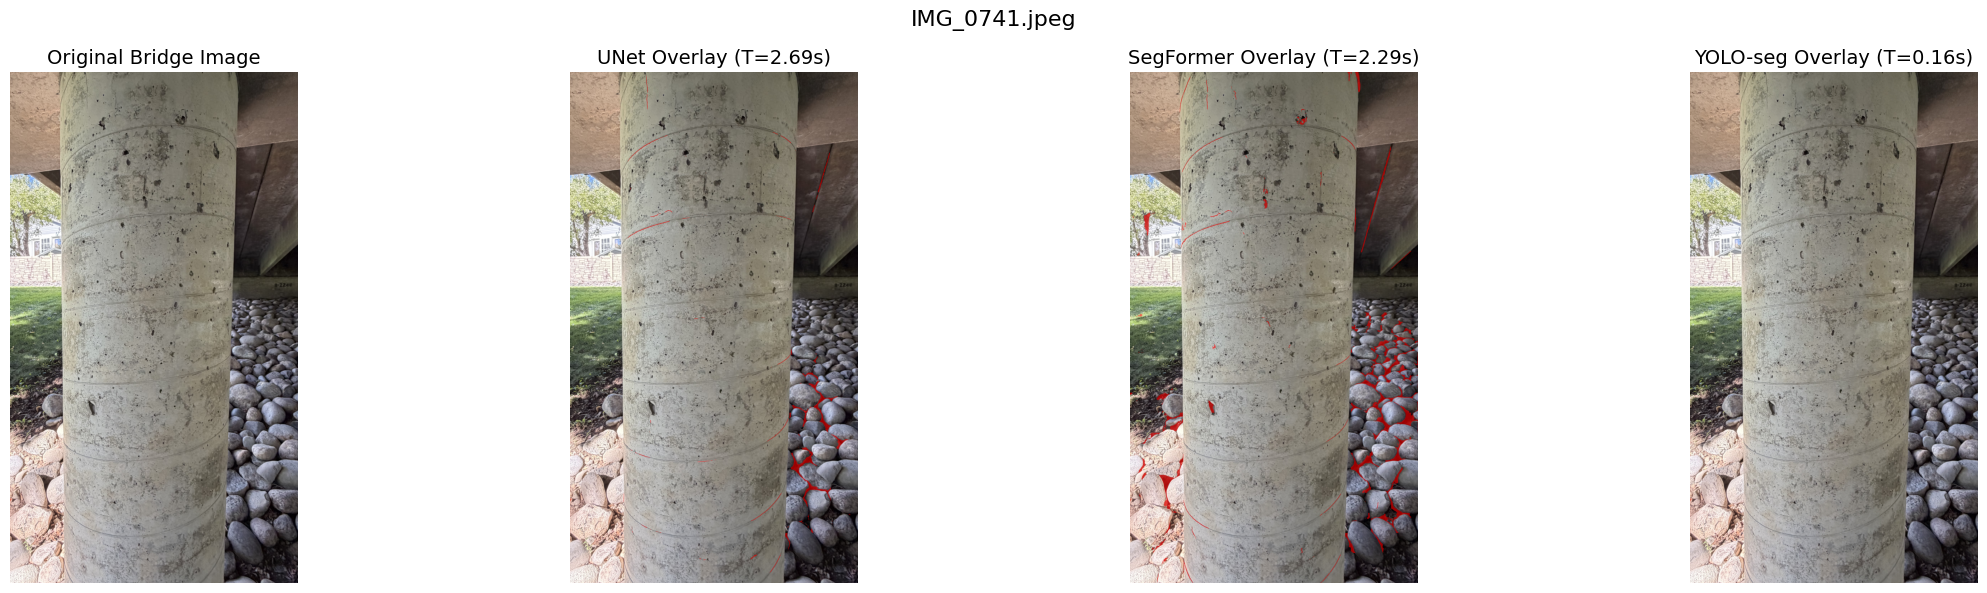

In [5]:
# Model checkpoint paths
unet_checkpoint = config.CHECKPOINT_DIR / "unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
segformer_checkpoint = config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
yolo_checkpoint = config.CHECKPOINT_DIR / "yolo_runs" / "yolo_seg_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pt"

# Load UNet, SegFormer, and YOLO models
print("Loading UNet model...")
unet_model = load_model("unet", unet_checkpoint, device=config.DEVICE)

print("Loading SegFormer model...")
segformer_model = load_model("segformer", segformer_checkpoint, device=config.DEVICE)

print("Loading YOLO model...")
yolo_model = load_model("yolo", yolo_checkpoint, device=config.DEVICE)


# Discover real bridge images
bridge_dir = config.DATA_ROOT / "reno_bridge_sample"
if not bridge_dir.exists():
    raise FileNotFoundError(f"Bridge image directory not found: {bridge_dir}")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
bridge_images = sorted(
    path for path in bridge_dir.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)

if not bridge_images:
    raise FileNotFoundError(f"No image files found in {bridge_dir}")

print(f"\nFound {len(bridge_images)} bridge image(s). Running inference...\n")

# Run inference and display 4 subimages side by side for each bridge image
for image_path in bridge_images:
    bridge_img = Image.open(image_path).convert("RGB")
    
    # 1. UNet prediction with patches + timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    unet_pred = predict_with_patches(
        image_path=image_path,
        model=unet_model,
        device=config.DEVICE,
        patch_size=448,
        stride=224,
    ) > 0.5
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    unet_time = time.perf_counter() - t0
    
    # 2. SegFormer prediction with patches + timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    segformer_pred = predict_with_patches(
        image_path=image_path,
        model=segformer_model,
        device=config.DEVICE,
        patch_size=448,
        stride=224,
    ) > 0.5
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    segformer_time = time.perf_counter() - t0
    
    # 3. YOLO-seg prediction + timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    yolo_pred = predict_yolo_mask(image_path, yolo_model, conf=0.15)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    yolo_time = time.perf_counter() - t0

    print(f"  {image_path.name:<60} | UNet: {unet_time:.2f}s | SegFormer: {segformer_time:.2f}s | YOLO: {yolo_time:.2f}s")
    
    # Create red overlays
    unet_overlay = create_red_overlay(bridge_img, unet_pred, alpha=0.6)
    segformer_overlay = create_red_overlay(bridge_img, segformer_pred, alpha=0.6)
    yolo_overlay = create_red_overlay(bridge_img, yolo_pred, alpha=0.6)

    # Plot 4 subimages side by side with execution time in titles
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(image_path.name, fontsize=16)

    axes[0].imshow(bridge_img)
    axes[0].set_title("Original Bridge Image", fontsize=14)
    axes[0].axis("off")

    axes[1].imshow(unet_overlay)
    axes[1].set_title(f"UNet Overlay (T={unet_time:.2f}s)", fontsize=14)
    axes[1].axis("off")

    axes[2].imshow(segformer_overlay)
    axes[2].set_title(f"SegFormer Overlay (T={segformer_time:.2f}s)", fontsize=14)
    axes[2].axis("off")

    axes[3].imshow(yolo_overlay)
    axes[3].set_title(f"YOLO-seg Overlay (T={yolo_time:.2f}s)", fontsize=14)
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()
